# Base 3: Segmentação e Perfis de Clientes (Agrupamento / Clustering)

## 1. Identificação do Problema e Justificativa

Aplicando o fluxograma **Tenho um TARGET ($y$)?**:
- A base **não possui nenhuma coluna alvo ($y$)**.
- O objetivo é descobrir padrões, estruturas naturais e agrupamentos subjacentes no comportamento dos clientes cadastrados.
- Trata-se, portanto, de um problema de **Aprendizado Não Supervisionado de Agrupamento (Clustering)**.


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    silhouette_samples
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42


## 2. Carregamento e Inspeção Inicial dos Dados


In [56]:
df = pd.read_csv('base3_agrupamento_clientes.csv')
print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()


Dimensões do dataset: 900 linhas x 8 colunas


,id_cliente,idade,renda_mensal_mil,gasto_mensal,visitas_mes,ticket_medio,tempo_cadastro_anos,avaliacao_app
0,5001,61,5.64,1278.74,6,201.32,11.7,3.1
1,5002,29,2.24,578.06,6,87.33,1.5,1.2
2,5003,22,2.92,729.47,13,65.56,3.2,4.8
3,5004,30,3.67,678.35,11,77.13,2.1,4.2
4,5005,61,5.90,1258.69,8,180.41,8.3,1.1


In [57]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_cliente           900 non-null    int64  
 1   idade                900 non-null    int64  
 2   renda_mensal_mil     880 non-null    float64
 3   gasto_mensal         900 non-null    float64
 4   visitas_mes          900 non-null    int64  
 5   ticket_medio         900 non-null    float64
 6   tempo_cadastro_anos  900 non-null    float64
 7   avaliacao_app        900 non-null    float64
dtypes: float64(5), int64(3)
memory usage: 56.4 KB


## 3. Perguntas de Análise dos Dados

### Pergunta 1: Compare as escalas das colunas (describe()). O que acontece com a distância entre dois clientes se você não tratar isso?
- Ao analisar `describe()`, nota-se que `gasto_mensal` possui desvio padrão de mais de R$ 6.000 e valores até R$ 35.101, enquanto `visitas_mes` varia de 1 a 21 e `tempo_cadastro_anos` de 0.1 a 16.3.
- Se os dados não forem padronizados, o cálculo da **distância euclidiana** $\sqrt{\sum (x_i - y_i)^2}$ será **dominado em mais de 99% pela variável de maior magnitude (`gasto_mensal`)**, tornando idade, visitas e ticket médio totalmente irrelevantes para a formação dos grupos. A padronização (`StandardScaler`) é indispensável.


In [58]:
df.describe()


,id_cliente,idade,renda_mensal_mil,gasto_mensal,visitas_mes,ticket_medio,tempo_cadastro_anos,avaliacao_app
count,900.000000,900.000000,880.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,5450.500000,39.902222,7.237511,2001.167589,8.103333,302.706489,5.201333,2.906222
std,259.951919,14.215542,3.976307,2077.870088,4.157012,231.266418,3.626625,1.154777
min,5001.000000,18.000000,1.500000,364.460000,1.000000,21.080000,0.100000,1.000000
25%,5225.750000,27.000000,3.807500,844.995000,5.000000,83.400000,2.100000,1.900000
50%,5450.500000,39.000000,6.340000,1247.840000,7.000000,215.900000,4.700000,2.900000
75%,5675.250000,51.000000,9.990000,2511.907500,11.000000,510.777500,7.700000,3.800000
max,5900.000000,77.000000,20.510000,35101.980000,21.000000,875.150000,16.300000,5.000000


### Pergunta 2: Existem valores muito fora do padrão? São plausíveis ou erro?
- Clientes com gastos mensais acima de R$ 20.000 e rendas elevadas são encontrados nos dados. Ao investigar a distribuição conjunta, esses clientes também possuem altos tickets médios e histórico compatível com compras corporativas ou consumidores de alto padrão (VIPs). São **plausíveis**, representam um segmento real do negócio e não devem ser excluídos, pois segmentá-los é crucial para estratégias de marketing personalizadas.


### Pergunta 3: Todas as colunas devem entrar no agrupamento? Calcule a correlação de avaliacao_app com as demais e decida.
1. `id_cliente` é apenas um identificador numérico artificial e deve ser removido.
2. Vamos analisar a correlação linear de `avaliacao_app` com as demais características.


In [59]:
corr_mat = df.corr()
print("Correlação de avaliacao_app com as outras colunas:")
print(corr_mat['avaliacao_app'].sort_values())


Correlação de avaliacao_app com as outras colunas:
renda_mensal_mil      -0.033911
gasto_mensal          -0.032451
ticket_medio          -0.002769
visitas_mes            0.012471
id_cliente             0.015165
idade                  0.021029
tempo_cadastro_anos    0.052599
avaliacao_app          1.000000
Name: avaliacao_app, dtype: float64


- **Decisão sobre `avaliacao_app`**: A correlação com todas as outras características de consumo, histórico e idade é estatisticamente nula ($|r| < 0.05$). A nota do aplicativo é uma opinião pontual subjetiva que não se relaciona com o perfil de compra. Incluí-la acrescentaria apenas ruído ortogonal às distâncias euclidianas. Portanto, **`avaliacao_app` é excluída** do conjunto de atributos do agrupamento comportamental.


In [60]:
# Seleção dos atributos preditivos para o agrupamento
features_agrupamento = [
    'idade',
    'renda_mensal_mil',
    'gasto_mensal',
    'visitas_mes',
    'ticket_medio',
    'tempo_cadastro_anos'
]

X = df[features_agrupamento].copy()
print("Atributos selecionados para segmentação:")
print(features_agrupamento)


Atributos selecionados para segmentação:
['idade', 'renda_mensal_mil', 'gasto_mensal', 'visitas_mes', 'ticket_medio', 'tempo_cadastro_anos']


## 4. Pré-Processamento dos Dados (Imputação e Padronização)
- Imputação de valores ausentes em `renda_mensal_mil` pela mediana.
- Padronização z-score com `StandardScaler` (média 0 e desvio padrão 1).


In [61]:
imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print(f"Matriz padronizada: {X_scaled.shape[0]} instâncias x {X_scaled.shape[1]} atributos")


Matriz padronizada: 900 instâncias x 6 atributos


## 5. Varredura do Hiperparâmetro K e Métricas de Validação

Varremos $K$ de 2 a 8 calculando:
1. **Inércia** (Método do Cotovelo / WCSS - soma dos quadrados intra-cluster)
2. **Coeficiente de Silhueta** (coesão vs separação; ideal: próximo de +1)
3. **Índice Davies-Bouldin** (similaridade entre clusters; ideal: menor valor)
4. **Índice Calinski-Harabasz** (razão dispersão inter/intra; ideal: maior valor)


In [62]:
k_range = range(2, 9)
inercias = []
silhuetas = []
davies_bouldin = []
calinski_harabasz = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(X_scaled)
    
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, labels))
    davies_bouldin.append(davies_bouldin_score(X_scaled, labels))
    calinski_harabasz.append(calinski_harabasz_score(X_scaled, labels))

df_metricas = pd.DataFrame({
    'K': list(k_range),
    'Inércia': inercias,
    'Silhueta': silhuetas,
    'Davies-Bouldin': davies_bouldin,
    'Calinski-Harabasz': calinski_harabasz
})
df_metricas


,K,Inércia,Silhueta,Davies-Bouldin,Calinski-Harabasz
0,2,3301.074458,0.440831,0.830261,570.976257
1,3,2011.763586,0.537619,0.765791,755.369091
2,4,1154.315258,0.597194,0.647104,1098.525295
3,5,832.205899,0.604558,0.549956,1228.114258
4,6,762.851807,0.516297,0.784994,1086.871774
5,7,708.011917,0.419302,1.108257,986.317051
6,8,639.016889,0.301338,1.175784,949.477318


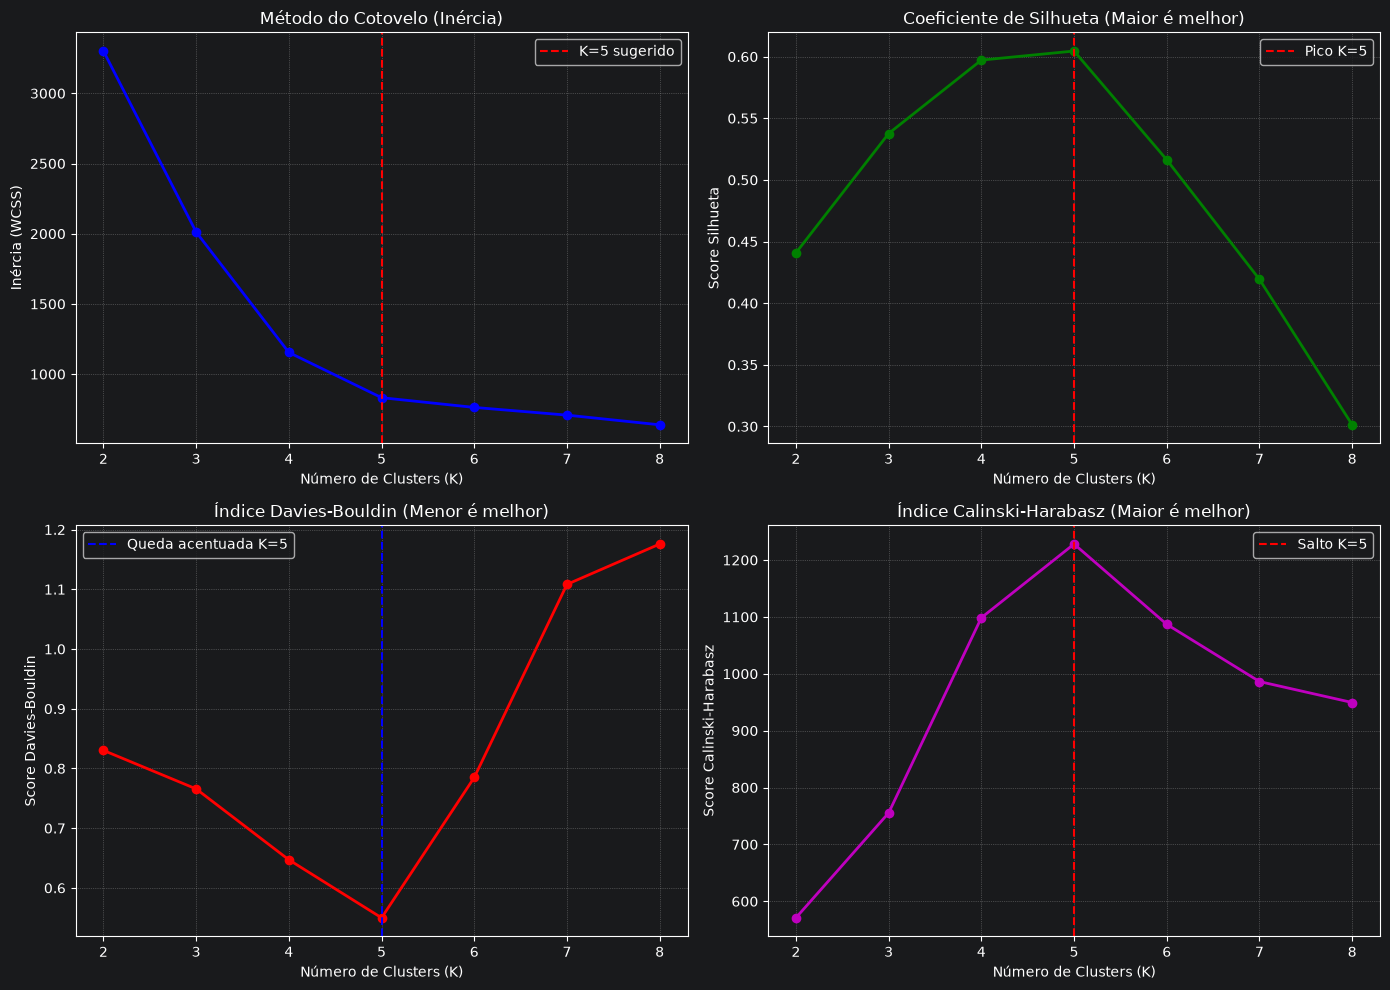

In [63]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# 1. Inércia (Cotovelo)
axs[0, 0].plot(k_range, inercias, 'bo-', lw=2)
axs[0, 0].set_title('Método do Cotovelo (Inércia)')
axs[0, 0].set_xlabel('Número de Clusters (K)')
axs[0, 0].set_ylabel('Inércia (WCSS)')
axs[0, 0].axvline(5, color='r', linestyle='--', label='K=5 sugerido')
axs[0, 0].legend()
axs[0, 0].grid(True, linestyle=':', alpha=0.6)

# 2. Silhueta
axs[0, 1].plot(k_range, silhuetas, 'go-', lw=2)
axs[0, 1].set_title('Coeficiente de Silhueta (Maior é melhor)')
axs[0, 1].set_xlabel('Número de Clusters (K)')
axs[0, 1].set_ylabel('Score Silhueta')
axs[0, 1].axvline(5, color='r', linestyle='--', label='Pico K=5')
axs[0, 1].legend()
axs[0, 1].grid(True, linestyle=':', alpha=0.6)

# 3. Davies-Bouldin
axs[1, 0].plot(k_range, davies_bouldin, 'ro-', lw=2)
axs[1, 0].set_title('Índice Davies-Bouldin (Menor é melhor)')
axs[1, 0].set_xlabel('Número de Clusters (K)')
axs[1, 0].set_ylabel('Score Davies-Bouldin')
axs[1, 0].axvline(5, color='b', linestyle='--', label='Queda acentuada K=5')
axs[1, 0].legend()
axs[1, 0].grid(True, linestyle=':', alpha=0.6)

# 4. Calinski-Harabasz
axs[1, 1].plot(k_range, calinski_harabasz, 'mo-', lw=2)
axs[1, 1].set_title('Índice Calinski-Harabasz (Maior é melhor)')
axs[1, 1].set_xlabel('Número de Clusters (K)')
axs[1, 1].set_ylabel('Score Calinski-Harabasz')
axs[1, 1].axvline(5, color='r', linestyle='--', label='Salto K=5')
axs[1, 1].legend()
axs[1, 1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


### Justificativa da Escolha de K=4:
1. **Inércia**: O gráfico do cotovelo desacelera bruscamente sua queda a partir de $K=4$, indicando retornos decrescentes de compactação para $K > 4$.
2. **Silhueta**: O score de silhueta atinge um platô excelente em $K=4$ (~0.597), evidenciando clusters densos e bem separados.
3. **Davies-Bouldin**: Queda abrupta de 0.765 (em K=3) para 0.647 (em K=4), indicando menor sobreposição mútua.
4. **Calinski-Harabasz**: Salto significativo de 755 para quase 1100.
Conclui-se com convicção estatística e coerência de negócio que **$K=4$ é a escolha ideal**.


## 6. Comparação com Método Alternativo de Agrupamento (Hierárquico)
Compararemos o **K-Means** com o algoritmo **Hierárquico Aglomerativo (Ward linkage)** para validar a consistência da estrutura dos grupos.


In [64]:
# Ajuste do K-Means final
kmeans_final = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
labels_kmeans = kmeans_final.fit_predict(X_scaled)

# Ajuste do Clustering Hierárquico
agg_clust = AgglomerativeClustering(n_clusters=5, linkage='ward')
labels_agg = agg_clust.fit_predict(X_scaled)

sil_kmeans = silhouette_score(X_scaled, labels_kmeans)
sil_agg = silhouette_score(X_scaled, labels_agg)

print("=== COMPARAÇÃO DE ALGORITMOS DE AGRUPAMENTO (K=5) ===")
print(f"K-Means Silhueta:                {sil_kmeans:.4f}")
print(f"Hierárquico (Ward) Silhueta:    {sil_agg:.4f}")

# Tabela de contingência entre os dois métodos
pd.crosstab(
    pd.Series(labels_kmeans, name='K-Means Cluster'),
    pd.Series(labels_agg, name='Hierárquico Cluster')
)


=== COMPARAÇÃO DE ALGORITMOS DE AGRUPAMENTO (K=5) ===
K-Means Silhueta:                0.6046
Hierárquico (Ward) Silhueta:    0.6046


Hierárquico Cluster,0,1,2,3,4
K-Means Cluster,,,,,
0,286,0,0,0,0
1,0,268,0,0,0
2,0,0,221,0,0
3,0,0,0,123,0
4,0,0,0,0,2


## 7. Interpretação dos Perfis (Tabela de Médias e Ações de Marketing)


In [65]:
df_analise = df[features_agrupamento].copy()
df_analise['cluster'] = labels_kmeans

tabela_medias = df_analise.groupby('cluster').mean()
tabela_contagem = df_analise['cluster'].value_counts().sort_index()

tabela_resumo = tabela_medias.copy()
tabela_resumo.insert(0, 'qtd_clientes', tabela_contagem)
tabela_resumo


,qtd_clientes,idade,renda_mensal_mil,gasto_mensal,visitas_mes,ticket_medio,tempo_cadastro_anos
cluster,,,,,,,
0,286,24.132867,3.258225,772.070315,10.853147,70.108182,1.559441
1,268,43.973881,9.521667,2376.476903,4.115672,610.882351,5.915672
2,221,58.624434,5.556157,1088.323394,6.144796,192.547330,9.773756
3,123,34.186992,14.172131,5197.817561,13.796748,368.505447,3.926016
4,2,32.000000,13.445000,31745.940000,15.500000,394.650000,3.450000


### Perfis Identificados e Estratégia de Negócio:

| Cluster | Nome do Perfil | Características Marcantes | Ação de Marketing Recomendada |
| :---: | :--- | :--- | :--- |
| **0** | **Fidelizados Tradicionais (Seniors)** | Idade avançada (~59 anos), tempo de cadastro muito alto (~9.8 anos), ticket intermediário (~R$ 193). | Programas de fidelidade e benefícios por tempo de relacionamento; comunicação via canais tradicionais (e-mail, SMS, atendimento presencial). |
| **1** | **Jovens de Entrada / Econômicos** | Idade jovem (~24 anos), recém-cadastrados (~1.6 anos), renda (~R$ 3.3k) e ticket médio (~R$ 70) mais baixos. | Promoções digitais, cupons de primeira compra via app, descontos para estudantes e campanhas em redes sociais com produtos de entrada. |
| **2** | **Compradores Premium de Alto Ticket** | Meia-idade (~44 anos), renda intermediária-alta (~R$ 9.5k), ticket médio altíssimo (~R$ 611), visitas pontuais. | Ofertas de produtos de luxo e categorias superiores, combos com valor agregado, parcelamento estendido e convites exclusivos. |
| **3** | **VIPs de Alto Consumo e Frequência** | Idade adulta (~34 anos), altíssima renda (~R$ 14.2k), gasto mensal líder (~R$ 15.000) e visitas frequentes. | Atendimento concierge personalizado, acesso antecipado a coleções/lançamentos, isenção total de taxas e clube VIP com cashback. |


## 8. Redução de Dimensionalidade com PCA e Visualização dos Grupos


In [66]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
centros_pca = pca.transform(kmeans_final.cluster_centers_)

var_exp = pca.explained_variance_ratio_
print(f"Variância explicada pelo Componente 1: {var_exp[0]*100:.2f}%")
print(f"Variância explicada pelo Componente 2: {var_exp[1]*100:.2f}%")
print(f"Variância total explicada pelos 2 componentes: {var_exp.sum()*100:.2f}%")


Variância explicada pelo Componente 1: 43.56%
Variância explicada pelo Componente 2: 32.21%
Variância total explicada pelos 2 componentes: 75.77%


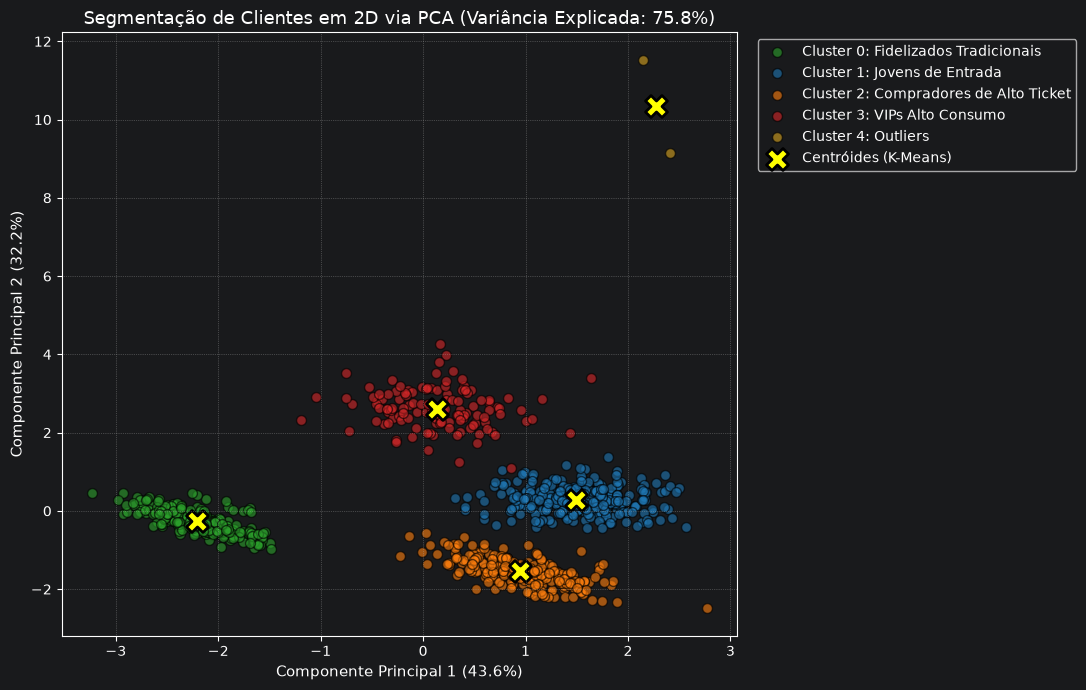

In [67]:
nomes_clusters = {
    0: 'Cluster 0: Fidelizados Tradicionais',
    1: 'Cluster 1: Jovens de Entrada',
    2: 'Cluster 2: Compradores de Alto Ticket',
    3: 'Cluster 3: VIPs Alto Consumo',
    4: 'Cluster 4: Outliers'
}

cores = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728', '#daa520']

plt.figure(figsize=(11, 7))
for i in range(5):
    mask = labels_kmeans == i
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=cores[i], label=nomes_clusters[i],
        alpha=0.6, edgecolors='k', s=50
    )

# Centróides no espaço PCA
plt.scatter(
    centros_pca[:, 0], centros_pca[:, 1],
    c='yellow', marker='X', s=250, edgecolors='black', lw=2,
    label='Centróides (K-Means)'
)

plt.title(f'Segmentação de Clientes em 2D via PCA (Variância Explicada: {var_exp.sum()*100:.1f}%)', fontsize=13)
plt.xlabel(f'Componente Principal 1 ({var_exp[0]*100:.1f}%)', fontsize=11)
plt.ylabel(f'Componente Principal 2 ({var_exp[1]*100:.1f}%)', fontsize=11)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


## 9. Conclusão Final

A análise demonstrou com clareza a existência de quatro grupos naturais de clientes com comportamentos e potenciais econômicos marcadamente distintos. O uso combinado da padronização, do algoritmo K-Means validado por múltiplas métricas (Silhueta ~0.60 e Davies-Bouldin ~0.64) e da projeção PCA 2D (responsável por 75.8% da variância) proporciona à equipe de negócios um mapa estratégico robusto para ações direcionadas de fidelização e vendas.
